# Chapter 13 · Exotic options: interactive demos

Companion to Chapter 13 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/13-exotics.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Throughout, under the risk-neutral measure $S_t = S_0 e^{\sigma X_t}$ with $X_t = W_t + \nu t$ and
$\nu = r/\sigma - \sigma/2$, as in Section 13.1 of the notes.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider

from ieor222 import exotics as ex
from ieor222.blackscholes import call
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
use_style()

## 1. The reflection principle

Left: a Brownian path, and the same path reflected about the level $m$ after its first passage at $m$
(Theorem 13.3 (i): the reflected path is again a Brownian motion). Paths that touch $m$ and end at $w<m$
are matched with paths that end at $2m-w$.

Right: the law of the maximum of $X_t = W_t+\nu t$ on $[0,1]$, from Theorem 13.3 (iii), against simulated
maxima. Taking the maximum over a grid of $n$ steps misses the tops of excursions between grid points, which
shifts the histogram to the left; sampling the maximum of the bridge between grid points exactly
(Remark 13.4) removes the bias even on a coarse grid.

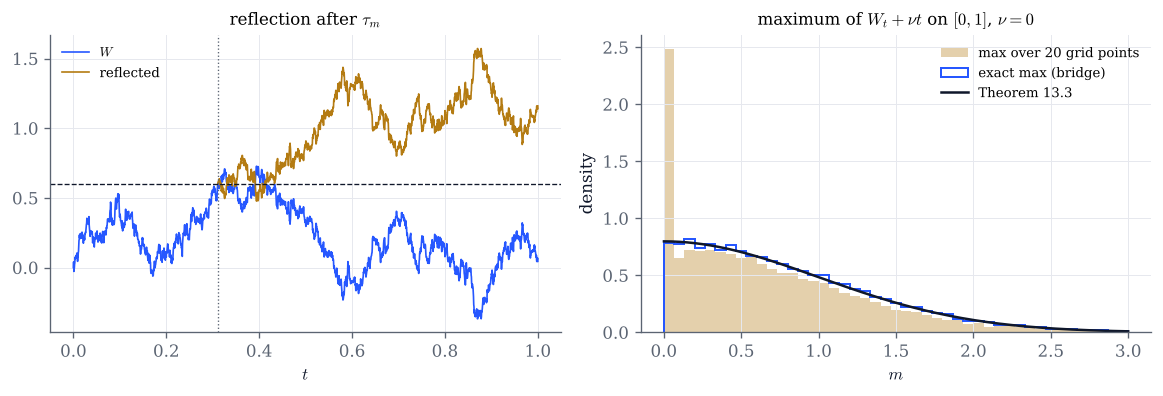

In [2]:
def reflection(m=0.6, nu=0.0, n_steps=20, seed=13):
    rng = np.random.default_rng(seed)
    n = 2000
    t = np.linspace(0, 1, n + 1)
    W = np.concatenate([[0.0], np.cumsum(rng.normal(0, np.sqrt(1 / n), n))])
    R = ex.reflect(W, m)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(t, W, color=COBALT, lw=1, label="$W$")
    hit = np.argmax(W >= m) if (W >= m).any() else None
    if hit is not None:
        ax.plot(t[hit:], R[hit:], color=GOLD, lw=1, label="reflected")
        ax.axvline(t[hit], color=GREY, ls=":", lw=0.8)
    ax.axhline(m, color=INK, ls="--", lw=0.8)
    ax.set(xlabel="$t$", title="path not reaching $m$" if hit is None else r"reflection after $\tau_m$")
    ax.legend(fontsize=8)

    X = ex.log_paths(1.0, n_steps, 20_000, nu, seed=seed + 1)
    grid_max = X.max(axis=1)
    bridge_max = ex.bridge_max_sample(X[:, :-1], X[:, 1:], 1.0 / n_steps, rng).max(axis=1)
    bins = np.linspace(0, 3, 46)
    ax2.hist(grid_max, bins=bins, density=True, color=GOLD, alpha=0.35, label=f"max over {n_steps} grid points")
    ax2.hist(bridge_max, bins=bins, density=True, histtype="step", color=COBALT, lw=1.2, label="exact max (bridge)")
    x = np.linspace(0.001, 3, 300)
    ax2.plot(x, ex.max_density(x, 1.0, nu), color=INK, lw=1.5, label="Theorem 13.3")
    ax2.set(xlabel="$m$", ylabel="density", title=rf"maximum of $W_t+\nu t$ on $[0,1]$, $\nu={nu:g}$")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

reflection()

In [3]:
# Explore: move the level, the drift and the number of grid steps.
interact(reflection,
         m=FloatSlider(value=0.6, min=0.1, max=1.5, step=0.05, continuous_update=False, description="m"),
         nu=FloatSlider(value=0.0, min=-1.5, max=1.5, step=0.1, continuous_update=False, description="ν"),
         n_steps=IntSlider(value=20, min=2, max=500, continuous_update=False, description="grid steps"),
         seed=IntSlider(value=13, min=0, max=50, continuous_update=False, description="seed"));

## 2. Barrier options and discrete monitoring

The up-and-out call pays $(S_T-K)^+$ unless the stock has reached $B$ before $T$. Proposition 13.5 gives its
price for continuous monitoring. Below, against the spot $S_0$:

* the closed form (continuous monitoring);
* Monte Carlo with the log-price sampled exactly at $m$ dates and each path weighted by its probability of
  not crossing $B$ between dates (Remark 13.4), an unbiased estimate of the same continuous price;
* Monte Carlo with the barrier checked at the $m$ dates only, which is what contracts do;
* the closed form with the barrier shifted to $Be^{0.5826\,\sigma\sqrt{T/m}}$ (Remark 13.7).

The European call is drawn for scale.

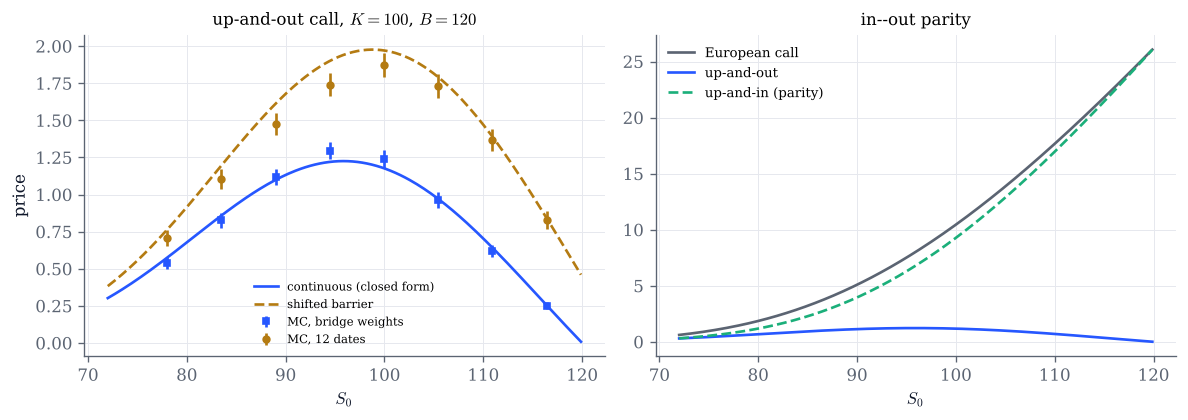

In [4]:
def barrier(K=100.0, B=120.0, sigma=0.2, r=0.05, T=1.0, m=12, n_paths=10_000):
    x = np.linspace(0.6 * B, B * 0.999, 200)
    xs = np.linspace(0.65 * B, 0.97 * B, 8)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
    ax.plot(x, ex.up_and_out_call(x, K, B, T, r, sigma), color=COBALT, label="continuous (closed form)")
    ax.plot(x, ex.up_and_out_call(x, K, ex.bgk_barrier(B, sigma, T, m), T, r, sigma), color=GOLD, ls="--",
            label="shifted barrier")
    cont = [ex.barrier_call_mc(s, K, B, T, r, sigma, n_monitor=m, n_paths=n_paths, continuous=True, seed=1) for s in xs]
    disc = [ex.barrier_call_mc(s, K, B, T, r, sigma, n_monitor=m, n_paths=n_paths, seed=2) for s in xs]
    ax.errorbar(xs, [c[0] for c in cont], yerr=[2 * c[1] for c in cont], fmt="s", ms=4, color=COBALT,
                label="MC, bridge weights")
    ax.errorbar(xs, [d[0] for d in disc], yerr=[2 * d[1] for d in disc], fmt="o", ms=4, color=GOLD,
                label=f"MC, {m} dates")
    ax.set(xlabel="$S_0$", ylabel="price", title=f"up-and-out call, $K={K:g}$, $B={B:g}$")
    ax.legend(fontsize=7)
    ax2.plot(x, call(x, K, T, r, sigma), color=GREY, label="European call")
    ax2.plot(x, ex.up_and_out_call(x, K, B, T, r, sigma), color=COBALT, label="up-and-out")
    ax2.plot(x, ex.up_and_in_call(x, K, B, T, r, sigma), color=GREEN, ls="--", label="up-and-in (parity)")
    ax2.set(xlabel="$S_0$", title="in--out parity")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

barrier()

In [5]:
# Explore: try a barrier close to the strike, a high volatility, or daily monitoring (m = 252).
interact(barrier,
         K=FloatSlider(value=100, min=60, max=140, step=5, continuous_update=False, description="K"),
         B=FloatSlider(value=120, min=105, max=200, step=5, continuous_update=False, description="B"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.05, min=-0.02, max=0.10, step=0.01, continuous_update=False, description="r"),
         T=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, continuous_update=False, description="T"),
         m=IntSlider(value=12, min=2, max=252, continuous_update=False, description="dates m"),
         n_paths=IntSlider(value=10_000, min=2_000, max=50_000, step=2_000, continuous_update=False, description="paths"));

## 3. Asian options: arithmetic, geometric, and Večeř's equation

The arithmetic Asian call pays $(\frac1T\int_0^TS_t\,dt-K)^+$. Its price is computed here by solving
Večeř's one-dimensional equation (Theorem 13.11) with Crank--Nicolson, and checked by Monte Carlo with the
geometric average as a control variate. The geometric Asian call has a closed form (Proposition 13.9) and is
a lower bound. The right panel shows Večeř's function $\tilde g(t,z)$, the price in units of the stock as a
function of $z=\Pi_t/S_t$; it equals $z$ for $z\ge\gamma(t)$, where exercise is certain.

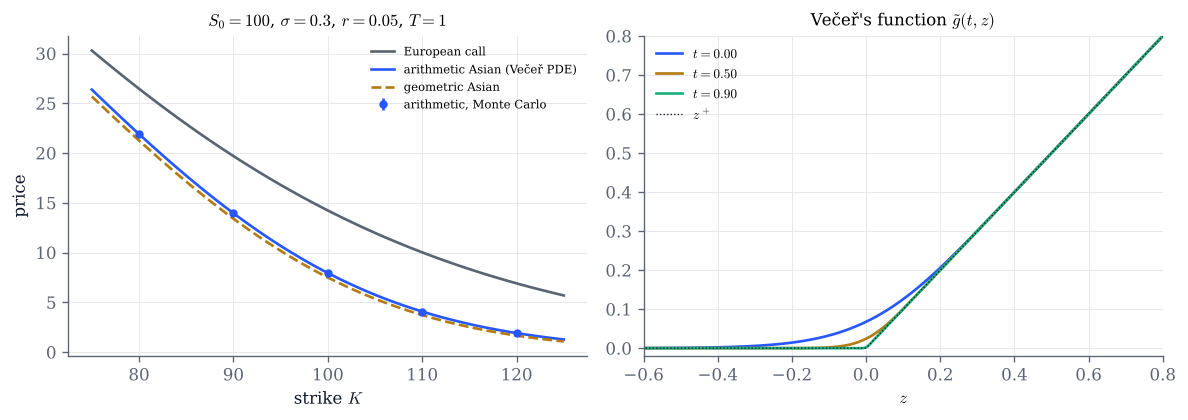

standard error divided by the control variate, K = 80..120: [26.8 26.5 23.8 19.1 13.8]


In [6]:
def asian(sigma=0.3, r=0.05, T=1.0, n_paths=10_000):
    S0 = 100.0
    Ks = np.linspace(80, 120, 5)
    grid = np.linspace(75, 125, 101)
    times = [0.0, 0.5 * T, 0.9 * T]
    z, g = ex.vecer_solve(T, r, sigma, n_z=801, n_t=400, times=times)
    vecer = S0 * np.interp(ex.vecer_gamma(0, T, r) - np.exp(-r * T) * grid / S0, z, g[0.0])
    mc = [ex.asian_call_mc(S0, k, T, r, sigma, n_steps=100, n_paths=n_paths, seed=3) for k in Ks]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
    ax.plot(grid, call(S0, grid, T, r, sigma), color=GREY, label="European call")
    ax.plot(grid, vecer, color=COBALT, label="arithmetic Asian (Večeř PDE)")
    ax.errorbar(Ks, [o["price"] for o in mc], yerr=[2 * o["se"] for o in mc], fmt="o", ms=4, color=COBALT,
                label="arithmetic, Monte Carlo")
    ax.plot(grid, ex.geometric_asian_call(S0, grid, T, r, sigma), color=GOLD, ls="--", label="geometric Asian")
    ax.set(xlabel="strike $K$", ylabel="price", title=rf"$S_0=100$, $\sigma={sigma:g}$, $r={r:g}$, $T={T:g}$")
    ax.legend(fontsize=7)
    for t, color in zip(times, (COBALT, GOLD, GREEN)):
        ax2.plot(z, g[t], color=color, label=f"$t={t:.2f}$")
    ax2.plot(z, np.maximum(z, 0), color=INK, lw=0.8, ls=":", label="$z^+$")
    ax2.set(xlim=(-0.6, 0.8), ylim=(-0.02, 0.8), xlabel="$z$", title=r"Večeř's function $\tilde g(t,z)$")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    ratio = [o["plain_se"] / o["se"] for o in mc]
    print("standard error divided by the control variate, K = 80..120:", np.round(ratio, 1))

asian()

In [7]:
interact(asian,
         sigma=FloatSlider(value=0.3, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.05, min=-0.02, max=0.15, step=0.01, continuous_update=False, description="r"),
         T=FloatSlider(value=1.0, min=0.25, max=3.0, step=0.25, continuous_update=False, description="T"),
         n_paths=IntSlider(value=10_000, min=2_000, max=40_000, step=2_000, continuous_update=False, description="paths"));

## 4. The perpetual American put

Proposition 13.12: with $\beta=2r/\sigma^2$, the perpetual put is worth $K-x$ below
$L^*=\beta K/(\beta+1)$ and $(K-L^*)(x/L^*)^{-\beta}$ above, and the two pieces meet with slope $-1$
(smooth fit). American puts with a finite maturity, computed in binomial trees (Theorem 4.13), are worth less
and approach it as the maturity grows.

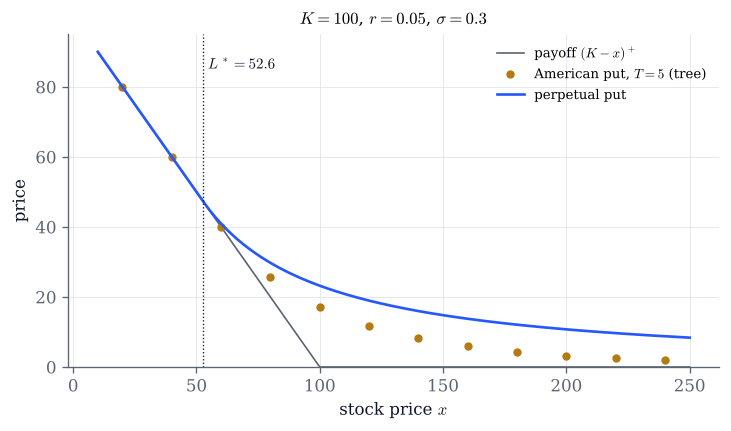

In [8]:
def perpetual(r=0.05, sigma=0.3, T=5.0):
    K = 100.0
    L = ex.perpetual_put_boundary(K, r, sigma)
    x = np.linspace(10, 250, 400)
    xs = np.linspace(20, 240, 12)
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.plot(x, np.maximum(K - x, 0), color=GREY, lw=1, label="payoff $(K-x)^+$")
    ax.plot(xs, [ex.american_put_binomial(s, K, T, r, sigma, n=300) for s in xs], "o", ms=4, color=GOLD,
            label=f"American put, $T={T:g}$ (tree)")
    ax.plot(x, ex.perpetual_put(x, K, r, sigma), color=COBALT, label="perpetual put")
    ax.axvline(L, color=INK, ls=":", lw=0.8)
    ax.text(L + 2, 85, f"$L^*={L:.1f}$", fontsize=9, color=INK)
    ax.set(xlabel="stock price $x$", ylabel="price", ylim=(0, 95), title=f"$K=100$, $r={r:g}$, $\\sigma={sigma:g}$")
    ax.legend(fontsize=8)
    plt.show()

perpetual()

In [9]:
# Explore: lengthen the maturity of the American put and watch it approach the perpetual one.
interact(perpetual,
         r=FloatSlider(value=0.05, min=0.01, max=0.15, step=0.01, continuous_update=False, description="r"),
         sigma=FloatSlider(value=0.3, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         T=FloatSlider(value=5.0, min=0.25, max=50.0, step=0.25, continuous_update=False, description="T"));

## Things to try

- In section 1, set the grid to 2 or 5 steps. How far is the histogram of grid maxima from the exact density,
  and why do the bridge maxima still match it?
- In section 2, put the barrier close to the spot (say $B=105$) and compare 12 and 252 monitoring dates. When
  is the shifted barrier a good approximation, and when does it fail?
- In section 2, the up-and-out price is not monotone in $S_0$. Where is its delta negative?
- In section 3, increase $\sigma$. Does the gap between the arithmetic and the geometric Asian call grow or
  shrink, and why does the control variate help less for high strikes?
- In section 4, let $r$ go to zero. What happens to $L^*$ and to the value of the perpetual put?